<a href="https://colab.research.google.com/github/pednekaratharva/Multi-Reference-Bank-Signature-Forgery-Detection-System/blob/main/Bank_Signature_Forgery_Detection_System_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
genuine_path = "/content/drive/MyDrive/signatures/full_org/"
forged_path = "/content/drive/MyDrive/signatures/full_forg/"

Preprocessing

In [ ]:
def preprocess_image(path):
    img = cv2.imread(path, 0)  # grayscale
    img = cv2.resize(img, (64, 64))  # resize
    return img

Feature extraction

In [ ]:
def extract_features(img):
    return img.flatten()

In [ ]:
import cv2
import numpy as np
import os
from sklearn.model_selection import train_test_split

X = []
y = []


IMAGE_EXTENSIONS = ('.png', '.jpg', '.jpeg', '.gif', '.bmp', '.tiff')

# Genuine = 1
for file_name in os.listdir(genuine_path):
    if file_name.lower().endswith(IMAGE_EXTENSIONS):
        img = preprocess_image(os.path.join(genuine_path, file_name))
        if img is not None: # Check if image was loaded successfully
            X.append(extract_features(img))
            y.append(1)

# Forged = 0
for file_name in os.listdir(forged_path):
    if file_name.lower().endswith(IMAGE_EXTENSIONS):
        img = preprocess_image(os.path.join(forged_path, file_name))
        if img is not None:
            X.append(extract_features(img))
            y.append(0)

X = np.array(X)
y = np.array(y)

print("Dataset Loaded:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Dataset Loaded: (2640, 4096)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 2112
Testing records: 528


Deccision tree model

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 1.0

Confusion Matrix:
 [[268   0]
 [  0 260]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       268
           1       1.00      1.00      1.00       260

    accuracy                           1.00       528
   macro avg       1.00      1.00      1.00       528
weighted avg       1.00      1.00      1.00       528



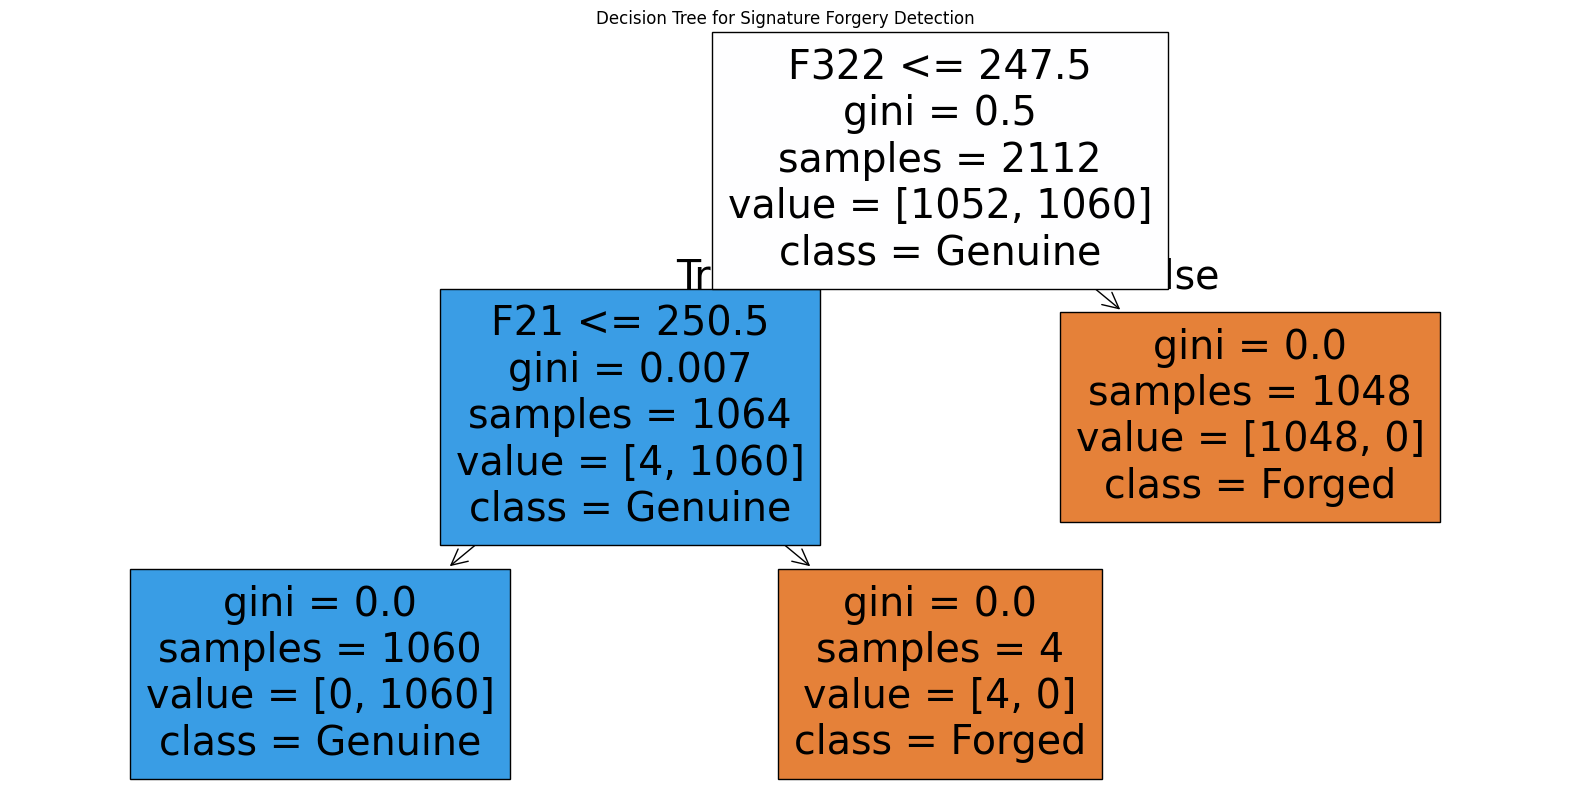

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(
    dt,
    filled=True,
    feature_names=[f'F{i}' for i in range(X.shape[1])],
    class_names=["Forged", "Genuine"],
)

plt.title("Decision Tree for Signature Forgery Detection")
plt.show()

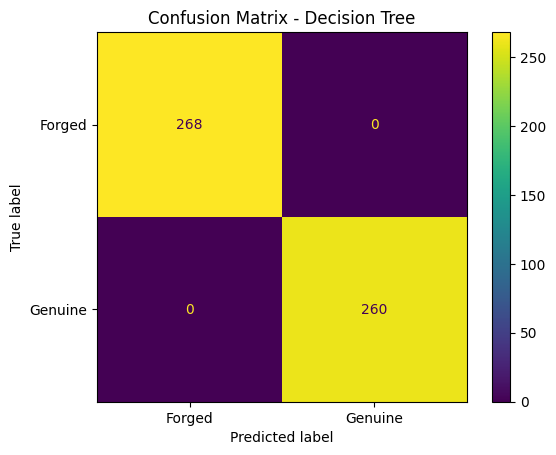

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_dt)

# Display it
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Forged", "Genuine"])

disp.plot()

plt.title("Confusion Matrix - Decision Tree")
plt.show()

K mean

In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X)

clusters = kmeans.labels_

print("K-Means Clustering Completed")

K-Means Clustering Completed


In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from sklearn.tree import DecisionTreeClassifier


def preprocess_image(image_path):

    img = cv2.imread(image_path, 0)
    if img is None:
        print(f"Warning: Could not read image {image_path}. Skipping.")
        return None
    img = cv2.resize(img, (64, 64))
    return img

def extract_features(img):
    if img is None:
        return None
    return img.flatten()
from google.colab import files
uploaded = files.upload()


if 'dt' not in locals() or not isinstance(dt, DecisionTreeClassifier) or not hasattr(dt, 'tree_'):

    dt = DecisionTreeClassifier()
    is_dt_trained = False
else:
    is_dt_trained = True



for file_name in uploaded.keys():
    processed_img = preprocess_image(file_name)

    if processed_img is not None:
        features = extract_features(processed_img)
        if features is not None:

            features = features.reshape(1, -1)

            try:
                if not is_dt_trained:
                    raise RuntimeError("Decision Tree model 'dt' is not trained. Please run prior cells to train the model.")

                result = dt.predict(features)

                prediction_label = "Genuine" if result[0] == 1 else "Forged"
                print(f"Prediction for {file_name}: {prediction_label}")

            except RuntimeError as e:
                print(f"Error making prediction for {file_name}: {e}")
                prediction_label = "Prediction Failed (Model not trained)"
            except Exception as e:
                print(f"An unexpected error occurred during prediction for {file_name}: {e}")
                prediction_label = "Prediction Failed (Error)"

            # Show image
            img = cv2.imread(file_name)
            if img is not None:
                plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
                plt.title(f"Prediction: {prediction_label}")
                plt.axis('off')
                plt.show()
            else:
                print(f"Could not display image {file_name}.")
        else:
            print(f"Could not extract features for image {file_name}.")
    else:
        print(f"Could not preprocess image {file_name}.")